# Phân tích XRD: HE M2BDC MOF 24 h và 48 h

Notebook phân tích dữ liệu **thô** của XRD_61028 (24 h), XRD_61102 (48 h) và đối chứng `xrd_bao1`; không ghi đè các tệp nguồn. Quy trình gồm kiểm tra dữ liệu, hiệu chỉnh nền AsLS, làm mượt chỉ để hỗ trợ nhận diện đỉnh, so khớp/vừa đỉnh, chỉ số diện tích và cường độ tương đối, so sánh đối chứng, trực quan hóa và xuất kết quả.

> Lưu ý: tương đồng toàn phổ không chứng minh cùng pha; chiều cao đỉnh không đo trực tiếp độ kết tinh; FWHM chưa hiệu chỉnh dụng cụ không cho kích thước tinh thể tuyệt đối. Bước sóng được để trống mặc định. Đối chứng thưa và không đều nên việc nhận diện đỉnh pha chỉ có tính chất sàng lọc.

In [4]:
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
from IPython.display import display
import numpy as np
import pandas as pd
from scipy import integrate, sparse
from scipy.optimize import least_squares, linear_sum_assignment
from scipy.signal import find_peaks, peak_widths, peak_prominences, savgol_filter
from scipy.sparse.linalg import spsolve

# ============================== CONFIG ==============================
CONFIG = {
    "sample_24h": {"label": "HE-MOF 24 h (XRD_61028)", "relative_path": Path("XRD_61028/raw/HE M2BDC MOF_Theta_2-Theta.txt")},
    "sample_48h": {"label": "HE-MOF 48 h (XRD_61102)", "relative_path": Path("XRD_61102/raw/HE H2BDC MOF 48_Theta_2-Theta.txt")},
    "reference": {"label": "xrd_bao1 (digitized literature pattern)", "relative_path": Path("XRD_61028/raw/xrd_bao1.txt"), "source_type": "digitized literature pattern"},
    "asls_lambda": 1e5,
    "asls_p": 0.01,
    "asls_iterations": 15,
    "savgol_window_points": 9,
    "savgol_polyorder": 3,
    "peak_prominence_fraction": 0.02,
    "peak_noise_sigma": 2.5,
    "peak_height_fraction": 0.015,
    "minimum_peak_distance_deg": 0.18,
    "reference_peak_min_prominence": 3.0,
    "reference_peak_min_separation_deg": 0.15,
    "peak_match_tolerance_deg": 0.25,
    "target_peak_regions_deg": {"P1": 9.1, "P2": 11.3, "P3": 17.9, "P4": 30.7, "P5": 32.8},
    "target_search_half_width_deg": 0.65,
    "overlap_gap_deg": 0.35,
    "fit_region_half_width_deg": 0.9,
    "fit_center_bound_deg": 0.20,
    "fit_min_fwhm_deg": 0.04,
    "fit_max_fwhm_deg": 1.4,
    "fit_max_nfev": 1200,
    "fit_min_r2": 0.80,
    "fit_max_relative_fwhm_se": 0.30,
    "fit_max_center_se_deg": 0.10,
    "scherrer_k": 0.9,
    "wavelength_angstrom": 1.5406,  # Cu Kα as specified by the user.
    "instrument_fwhm_deg_2theta": None,  # No instrument standard supplied; do not deconvolve pseudo-Voigt widths.
    "output_dir": Path("XRD_61028/analysis/xrd_results"),
    "figure_dpi": 300,
    "figure_size": (10, 5.5),
}

_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next((p for root in _candidates for p in (root, root / "XRD", root / "projects", root / "projects" / "XRD")
                     if all((p / f"XRD_{n}" / "raw").is_dir() for n in ("61028", "61102"))), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Không tìm thấy thư mục XRD_61028/raw và XRD_61102/raw")
for key in ("sample_24h", "sample_48h", "reference"):
    CONFIG[key]["path"] = PROJECT_ROOT / CONFIG[key]["relative_path"]


def load_xy(path):
    raw = pd.read_csv(path, sep=r"\s+", comment="#", header=None, usecols=[0, 1],
                      names=["two_theta", "intensity"], engine="python")
    raw["two_theta"] = pd.to_numeric(raw["two_theta"], errors="coerce")
    raw["intensity"] = pd.to_numeric(raw["intensity"], errors="coerce")
    finite = np.isfinite(raw[["two_theta", "intensity"]]).all(axis=1)
    clean = raw.loc[finite].copy()
    if len(clean) < 10:
        raise ValueError(f"Không đủ 10 điểm dữ liệu hữu hạn: {path}")
    theta_input = clean["two_theta"].to_numpy(float)
    duplicate_rows = int(clean["two_theta"].duplicated(keep=False).sum())
    monotonic_original = bool(np.all(np.diff(theta_input) > 0))
    clean = clean.groupby("two_theta", as_index=False, sort=True)["intensity"].mean()
    theta = clean["two_theta"].to_numpy(float)
    intensity = clean["intensity"].to_numpy(float)
    steps = np.diff(theta)
    if np.any(steps <= 0):
        raise ValueError(f"Trục 2theta không tăng sau khi xử lý điểm trùng: {path}")
    median_step = float(np.median(steps))
    report = {
        "file": str(path), "input_rows": len(raw), "invalid_rows": int((~finite).sum()),
        "duplicate_theta_rows": duplicate_rows, "monotonic_original": monotonic_original,
        "unique_points": len(theta), "two_theta_min_deg": float(theta.min()),
        "two_theta_max_deg": float(theta.max()), "step_median_deg": median_step,
        "step_min_deg": float(steps.min()), "step_max_deg": float(steps.max()),
        "step_cv": float(np.std(steps) / median_step) if median_step else np.nan,
    }
    return {"theta_raw": theta, "intensity_raw": intensity, "report": report}


sample_keys = ("sample_24h", "sample_48h")
spectra = {}
for key in (*sample_keys, "reference"):
    spec = load_xy(CONFIG[key]["path"])
    spec["label"] = CONFIG[key]["label"]
    spectra[key] = spec

# Only measured samples enter the uniform-grid processing pipeline.
for key in sample_keys:
    spec = spectra[key]
    x, y = spec["theta_raw"], spec["intensity_raw"]
    step = spec["report"]["step_median_deg"]
    if spec["report"]["step_cv"] > 1e-3:
        grid = np.arange(x[0], x[-1] + step * 0.25, step)
        grid = grid[grid <= x[-1]]
        spec["theta"], spec["intensity"] = grid, np.interp(grid, x, y)
        spec["sample_regridded_for_processing"] = True
    else:
        spec["theta"], spec["intensity"] = x.copy(), y.copy()
        spec["sample_regridded_for_processing"] = False

quality_report = pd.DataFrame([s["report"] for s in spectra.values()]).set_index("file")
display(quality_report)
common_sample_range = (
    max(spectra[k]["theta_raw"].min() for k in sample_keys),
    min(spectra[k]["theta_raw"].max() for k in sample_keys),
)
common_all_range = (
    max(spectra[k]["theta_raw"].min() for k in (*sample_keys, "reference")),
    min(spectra[k]["theta_raw"].max() for k in (*sample_keys, "reference")),
)
if common_sample_range[0] >= common_sample_range[1] or common_all_range[0] >= common_all_range[1]:
    raise ValueError("Không có miền 2theta chung hợp lệ")
print(f"Miền chung hai mẫu: {common_sample_range[0]:.4f}–{common_sample_range[1]:.4f}°")
print(f"Miền chung hai mẫu và reference: {common_all_range[0]:.4f}–{common_all_range[1]:.4f}°")
print("Reference là phổ đã số hóa từ tài liệu; giữ nguyên các điểm gốc duy nhất, không nội suy/hiệu chỉnh nền/làm mượt để định vị peak.")


,input_rows,invalid_rows,duplicate_theta_rows,monotonic_original,unique_points,two_theta_min_deg,two_theta_max_deg,step_median_deg,step_min_deg,step_max_deg,step_cv
file,,,,,,,,,,,
/var/local/DE_AN/XRD/XRD_61028/raw/HE M2BDC MOF_Theta_2-Theta.txt,3751,0,0,True,3751,5.000,80.00000,0.0200,0.02000,0.02000,1.893855e-13
/var/local/DE_AN/XRD/XRD_61102/raw/HE H2BDC MOF 48_Theta_2-Theta.txt,3751,0,0,True,3751,5.000,80.00000,0.0200,0.02000,0.02000,1.893855e-13
/var/local/DE_AN/XRD/XRD_61028/raw/xrd_bao1.txt,114,0,17,False,104,5.293,40.08037,0.2707,0.02209,1.10489,1.033921e+00


Miền chung hai mẫu: 5.0000–80.0000°
Miền chung hai mẫu và reference: 5.2930–40.0804°
Reference là phổ đã số hóa từ tài liệu; giữ nguyên các điểm gốc duy nhất, không nội suy/hiệu chỉnh nền/làm mượt để định vị peak.


## I. Tiền xử lý

AsLS ước lượng nền bất đối xứng bằng cách lặp trọng số giữa phần nền và phần tín hiệu. Lưu phổ thô, phổ trừ nền, phổ làm mượt và hai dạng chuẩn hóa riêng. Savitzky–Golay chỉ hỗ trợ phát hiện đỉnh; các thông số diện tích/FWHM được tính từ phổ đã hiệu chỉnh nền, không dùng phổ chuẩn hóa.

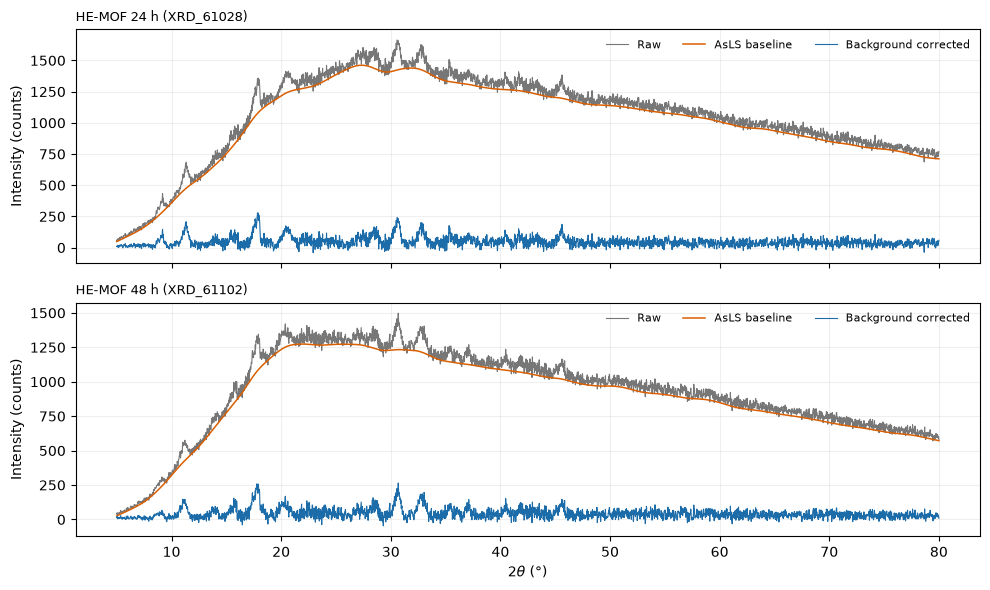

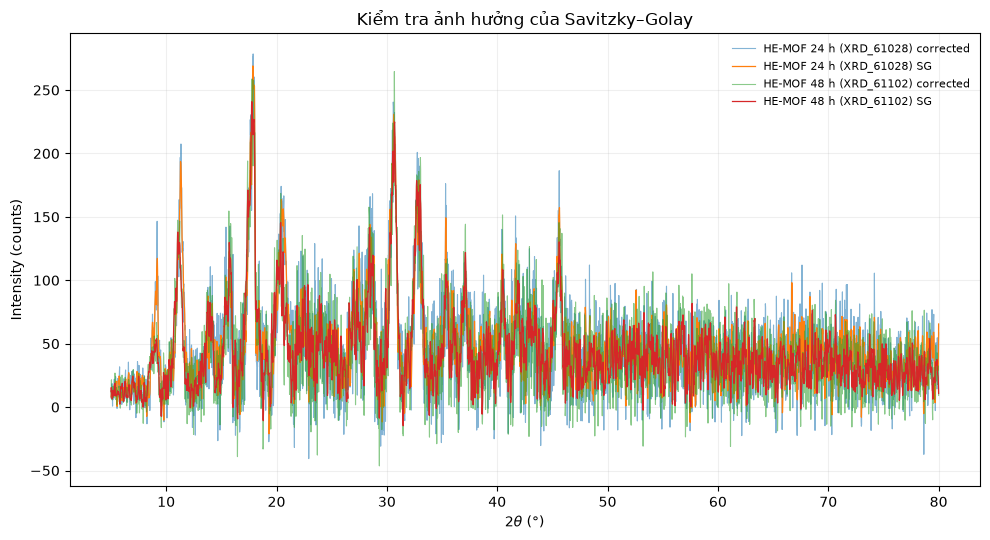

Savitzky–Golay: window=9, polyorder=3; chỉ áp dụng cho hai mẫu.


In [5]:
def asls_baseline(y, lam=1e5, p=0.01, iterations=15):
    if not 0 < p < 1 or lam <= 0:
        raise ValueError("AsLS yêu cầu lambda > 0 và 0 < p < 1")
    n = len(y)
    if n < 3:
        raise ValueError("AsLS cần tối thiểu 3 điểm")
    difference = sparse.diags([1, -2, 1], [0, 1, 2], shape=(n - 2, n), format="csc", dtype=float)
    penalty = lam * (difference.T @ difference)
    weights = np.ones(n)
    for _ in range(iterations):
        W = sparse.spdiags(weights, 0, n, n)
        baseline = spsolve(W + penalty, weights * y)
        weights = np.where(y > baseline, p, 1 - p)
    return baseline


def odd_window(requested, n):
    window = min(int(requested), n if n % 2 else n - 1)
    if window % 2 == 0:
        window -= 1
    if window <= CONFIG["savgol_polyorder"]:
        raise ValueError("Không đủ điểm cho cửa sổ Savitzky–Golay")
    return window


for key in sample_keys:
    spec = spectra[key]
    theta, y = spec["theta"], spec["intensity"]
    baseline = asls_baseline(y, CONFIG["asls_lambda"], CONFIG["asls_p"], CONFIG["asls_iterations"])
    corrected = y - baseline
    window = odd_window(CONFIG["savgol_window_points"], len(y))
    smoothed = savgol_filter(corrected, window, CONFIG["savgol_polyorder"])
    positive = np.clip(corrected, 0, None)
    maximum = float(positive.max())
    area = float(integrate.trapezoid(positive, theta))
    if maximum <= 0 or area <= 0:
        raise ValueError(f"Không có tín hiệu dương sau hiệu chỉnh nền: {spec['label']}")
    spec.update({"baseline": baseline, "corrected": corrected, "smoothed": smoothed,
                 "max_norm": positive / maximum, "area_norm": positive / area,
                 "savgol_window_used": window})

fig, axes = plt.subplots(len(sample_keys), 1, figsize=(10, 6), sharex=True)
for ax, key in zip(axes, sample_keys):
    spec = spectra[key]
    ax.plot(spec["theta"], spec["intensity"], color="#777777", lw=0.8, label="Raw")
    ax.plot(spec["theta"], spec["baseline"], color="#d95f02", lw=1.1, label="AsLS baseline")
    ax.plot(spec["theta"], spec["corrected"], color="#1b6ca8", lw=0.8, label="Background corrected")
    ax.set_ylabel("Intensity (counts)")
    ax.set_title(spec["label"], loc="left", fontsize=9)
    ax.legend(frameon=False, fontsize=8, ncol=3)
    ax.grid(alpha=0.2)
axes[-1].set_xlabel(r"2$\theta$ (°)")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=CONFIG["figure_size"])
for key in sample_keys:
    spec = spectra[key]
    ax.plot(spec["theta"], spec["corrected"], lw=0.8, alpha=0.55, label=spec["label"] + " corrected")
    ax.plot(spec["theta"], spec["smoothed"], lw=0.9, label=spec["label"] + " SG")
ax.set(xlabel=r"2$\theta$ (°)", ylabel="Intensity (counts)", title="Kiểm tra ảnh hưởng của Savitzky–Golay")
ax.legend(frameon=False, fontsize=8)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()
print(f"Savitzky–Golay: window={CONFIG['savgol_window_points']}, polyorder={CONFIG['savgol_polyorder']}; chỉ áp dụng cho hai mẫu.")


## II. Phát hiện và fit năm peak mục tiêu

Các giá trị 9.1°, 11.3°, 17.9°, 30.7° và 32.8° chỉ xác định vùng tìm kiếm. Vị trí fit được tự do dịch chuyển quanh peak phát hiện. Chỉ fit các mẫu; nhóm component lân cận được fit đồng thời. Nếu chất lượng kém, bảng dùng vị trí phát hiện kèm trạng thái cảnh báo và để trống FWHM/D_app.


In [6]:
def pvoigt_component(x, amplitude, center, fwhm, eta):
    z = (x - center) / fwhm
    return amplitude * (eta / (1 + 4 * z**2) + (1 - eta) * np.exp(-4 * np.log(2) * z**2))


def robust_sigma(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if not len(values):
        return 0.0
    return float(1.4826 * np.median(np.abs(values - np.median(values))))


def detect_sample_peaks(spec):
    y = spec["smoothed"]
    dynamic = float(np.ptp(y))
    noise = robust_sigma(spec["corrected"] - y)
    if dynamic <= 0:
        return pd.DataFrame(columns=["index", "position_deg", "intensity", "prominence", "relative_intensity_pct", "detected_width_deg"])
    step = float(np.median(np.diff(spec["theta"])))
    distance = max(1, int(np.ceil(CONFIG["minimum_peak_distance_deg"] / step)))
    prominence_threshold = max(CONFIG["peak_prominence_fraction"] * dynamic,
                               CONFIG["peak_noise_sigma"] * noise)
    indices, props = find_peaks(y, prominence=prominence_threshold,
                                height=CONFIG["peak_height_fraction"] * dynamic,
                                distance=distance)
    peaks = pd.DataFrame({"index": indices, "position_deg": spec["theta"][indices],
                          "intensity": spec["corrected"][indices],
                          "prominence": props["prominences"]})
    peaks["relative_intensity_pct"] = 100 * peaks["intensity"].clip(lower=0) / max(float(spec["corrected"].max()), np.finfo(float).eps)
    if len(peaks):
        peaks["detected_width_deg"] = peak_widths(y, indices, rel_height=0.5)[0] * step
    else:
        peaks["detected_width_deg"] = pd.Series(dtype=float)
    return peaks.sort_values("position_deg").reset_index(drop=True)


def detect_reference_peaks(spec):
    # xrd_bao1 is digitized literature data: use only its unique source points.
    x, y = spec["theta_raw"], spec["intensity_raw"]
    indices, props = find_peaks(y, prominence=CONFIG["reference_peak_min_prominence"])
    candidates = sorted(zip(indices, props["prominences"]), key=lambda item: item[1], reverse=True)
    selected = []
    for index, prominence in candidates:
        if all(abs(float(x[index] - x[other])) >= CONFIG["reference_peak_min_separation_deg"] for other in selected):
            selected.append(index)
    selected.sort(key=lambda i: x[i])
    return pd.DataFrame({"position_deg": x[selected], "intensity": y[selected],
                         "prominence": [float(x) for x in [peak_prominences(y, np.asarray(selected, dtype=int))[0][i] for i in range(len(selected))]]})


def one_to_one_matches(left, right, tolerance):
    left = np.asarray(left, dtype=float)
    right = np.asarray(right, dtype=float)
    left_valid = np.flatnonzero(np.isfinite(left))
    right_valid = np.flatnonzero(np.isfinite(right))
    if not len(left_valid) or not len(right_valid):
        return []
    distances = np.abs(left[left_valid, None] - right[None, right_valid])
    # Dummy columns represent unmatched left peaks. Their cost makes the
    # assignment maximize the number of in-tolerance pairs before minimizing shifts.
    unmatched_cost = (min(len(left_valid), len(right_valid)) + 1) * max(float(tolerance), 1e-6)
    costs = np.full((len(left_valid), len(right_valid) + len(left_valid)), 2 * unmatched_cost)
    costs[:, :len(right_valid)] = np.where(distances <= tolerance, distances, 2 * unmatched_cost)
    costs[:, len(right_valid):] = unmatched_cost
    rows, cols = linear_sum_assignment(costs)
    matches = []
    for row, col in zip(rows, cols):
        if col < len(right_valid) and distances[row, col] <= tolerance:
            matches.append((int(left_valid[row]), int(right_valid[col]), float(distances[row, col])))
    return sorted(matches, key=lambda match: left[match[0]])


def fit_peak_group(spec, candidate_rows, group_id):
    x, y = spec["theta"], spec["corrected"]
    positions = np.asarray([float(row["position_deg"]) for row in candidate_rows])
    half_width = CONFIG["fit_region_half_width_deg"]
    x_min = max(float(x.min()), float(positions.min() - half_width))
    x_max = min(float(x.max()), float(positions.max() + half_width))
    mask = (x >= x_min) & (x <= x_max)
    xx, yy = x[mask], y[mask]
    step = float(np.median(np.diff(xx))) if len(xx) > 1 else np.nan
    n_components = len(candidate_rows)
    if len(xx) < 4 * n_components + 5 or not np.isfinite(step):
        return [], "insufficient_fit_points"
    edge_n = max(2, len(yy) // 6)
    offset0 = float(np.median(np.r_[yy[:edge_n], yy[-edge_n:]]))
    lower, initial, upper = [], [], []
    for row in candidate_rows:
        pos = float(row["position_deg"])
        local_mask = np.abs(xx - pos) <= min(0.15, half_width / 2)
        amp = max(float(np.max(yy[local_mask]) - offset0), np.finfo(float).eps) if local_mask.any() else max(float(yy.max() - offset0), 1.0)
        width = float(row.get("detected_width_deg", 0.12))
        width = float(np.clip(width, max(CONFIG["fit_min_fwhm_deg"], 2 * step),
                              CONFIG["fit_max_fwhm_deg"] * 0.8))
        center_bound = CONFIG["fit_center_bound_deg"]
        initial.extend([amp, pos, width, 0.5])
        lower.extend([0.0, pos - center_bound, CONFIG["fit_min_fwhm_deg"], 0.0])
        upper.extend([np.inf, pos + center_bound, CONFIG["fit_max_fwhm_deg"], 1.0])
    initial.append(offset0)
    lower.append(-np.inf)
    upper.append(np.inf)

    def model(params):
        result = np.full_like(xx, params[-1], dtype=float)
        for component in range(n_components):
            amp, center, width, eta = params[4*component:4*component+4]
            result += pvoigt_component(xx, amp, center, width, eta)
        return result

    try:
        result = least_squares(lambda params: model(params) - yy, initial,
                               bounds=(lower, upper), max_nfev=CONFIG["fit_max_nfev"],
                               x_scale="jac")
        fitted = model(result.x)
        residual = yy - fitted
        sse = float(np.dot(residual, residual))
        rmse = float(np.sqrt(np.mean(residual**2)))
        ss_total = float(np.sum((yy - yy.mean())**2))
        r2 = 1 - sse / ss_total if ss_total > 0 else np.nan
        dof = len(yy) - len(result.x)
        covariance = np.linalg.pinv(result.jac.T @ result.jac) * (sse / dof) if dof > 0 else np.full((len(result.x), len(result.x)), np.nan)
        errors = np.sqrt(np.clip(np.diag(covariance), 0, None))
        records = []
        for component, source in enumerate(candidate_rows):
            amp, center, width, eta = result.x[4*component:4*component+4]
            component_error = errors[4*component:4*component+4]
            center_at_bound = min(center - lower[4*component+1], upper[4*component+1] - center) < 1e-4
            width_at_bound = width - CONFIG["fit_min_fwhm_deg"] < 1e-4 or CONFIG["fit_max_fwhm_deg"] - width < 1e-4
            center_error_bad = not np.isfinite(component_error[1]) or component_error[1] > CONFIG["fit_max_center_se_deg"]
            width_error_bad = not np.isfinite(component_error[2]) or component_error[2] / width > CONFIG["fit_max_relative_fwhm_se"]
            reliable = bool(result.success and np.isfinite(r2) and r2 >= CONFIG["fit_min_r2"]
                            and not center_at_bound and not width_at_bound
                            and not center_error_bad and not width_error_bad)
            eta_area = eta * np.pi * width / 2 + (1-eta) * width * np.sqrt(np.pi / (4*np.log(2)))
            area = float(amp * eta_area)
            records.append({
                "fit_group_id": group_id, "fit_group_size": n_components,
                "detected_position_deg": float(source["position_deg"]),
                "fit_center_deg": float(center), "fit_center_se_deg": float(component_error[1]),
                "fwhm_observed_deg": float(width), "fwhm_se_deg": float(component_error[2]),
                "fit_area": area, "fit_amplitude": float(amp), "fit_eta_lorentzian": float(eta),
                "fit_offset": float(result.x[-1]), "fit_rmse": rmse, "fit_r2": float(r2),
                "fit_reduced_chi2": np.nan, "fit_status": "ok" if reliable else
                    "unreliable_fit:" + ",".join(
                        reason for reason, failed in [
                            ("low_r2", not np.isfinite(r2) or r2 < CONFIG["fit_min_r2"]),
                            ("center_at_bound", center_at_bound),
                            ("width_at_bound", width_at_bound),
                            ("center_uncertainty", center_error_bad),
                            ("width_uncertainty", width_error_bad),
                            ("optimizer", not result.success),
                        ] if failed),
                "fit_reliable": reliable, "fit_residual": residual.copy(), "fit_x": xx.copy(),
                "source_peak_prominence": float(source["prominence"]),
            })
        return records, "ok" if result.success else "optimizer_failed"
    except (ValueError, FloatingPointError, np.linalg.LinAlgError) as exc:
        return [], f"fit_failed:{type(exc).__name__}"


def scherrer_apparent_size(center_deg, fwhm_observed_deg):
    if CONFIG["wavelength_angstrom"] is None or not np.isfinite(fwhm_observed_deg) or fwhm_observed_deg <= 0:
        return np.nan
    theta_bragg = np.deg2rad(float(center_deg) / 2)
    beta_observed = np.deg2rad(float(fwhm_observed_deg))
    return CONFIG["scherrer_k"] * CONFIG["wavelength_angstrom"] / (beta_observed * np.cos(theta_bragg))


peak_tables = {key: detect_sample_peaks(spectra[key]) for key in sample_keys}
ref_peaks = detect_reference_peaks(spectra["reference"])
for key in sample_keys:
    print(f"{spectra[key]['label']}: {len(peak_tables[key])} sample peak candidates after noise-aware prominence filtering")
print(f"Reference: {len(ref_peaks)} raw-point local maxima; no reference width/area fitting.")

target_analysis = {key: [] for key in sample_keys}
fit_component_records = {key: [] for key in sample_keys}
for key in sample_keys:
    candidates = peak_tables[key]
    for peak_id, search_center in CONFIG["target_peak_regions_deg"].items():
        local = candidates[np.abs(candidates["position_deg"] - search_center) <= CONFIG["target_search_half_width_deg"]].to_dict("records")
        if not local:
            target_analysis[key].append({
                "peak_id": peak_id, "search_center_deg": search_center, "detected_position_deg": np.nan,
                "position_deg": np.nan, "position_source": "not_detected", "fwhm_observed_deg": np.nan,
                "fwhm_se_deg": np.nan, "d_app_angstrom": np.nan, "fit_r2": np.nan,
                "fit_rmse": np.nan, "fit_status": "not_detected", "overlap_fit": False,
            })
            continue
        nearest = min(local, key=lambda row: abs(float(row["position_deg"]) - search_center))
        group = [row for row in local if abs(float(row["position_deg"]) - float(nearest["position_deg"])) <= CONFIG["overlap_gap_deg"]]
        fit_group_id = f"{key}_{peak_id}"
        fitted, status = fit_peak_group(spectra[key], group, fit_group_id)
        fit_component_records[key].extend(fitted)
        if fitted:
            selected = min(fitted, key=lambda row: abs(row["fit_center_deg"] - search_center))
            fit_ok = selected["fit_reliable"]
            used_position = selected["fit_center_deg"] if fit_ok else selected["detected_position_deg"]
            position_source = "pseudo-Voigt fit" if fit_ok else "detected-peak fallback"
            width = selected["fwhm_observed_deg"] if fit_ok else np.nan
            d_app = scherrer_apparent_size(used_position, width) if fit_ok else np.nan
            fit_status = selected["fit_status"]
            record = {
                "peak_id": peak_id, "search_center_deg": search_center,
                "detected_position_deg": selected["detected_position_deg"], "position_deg": used_position,
                "position_source": position_source, "fwhm_observed_deg": width,
                "fwhm_se_deg": selected["fwhm_se_deg"] if fit_ok else np.nan,
                "d_app_angstrom": d_app, "fit_r2": selected["fit_r2"],
                "fit_rmse": selected["fit_rmse"], "fit_status": fit_status,
                "overlap_fit": len(group) > 1, "overlap_components": len(group),
                "fit_group_id": fit_group_id, "fit_center_se_deg": selected["fit_center_se_deg"] if fit_ok else np.nan,
            }
        else:
            record = {
                "peak_id": peak_id, "search_center_deg": search_center,
                "detected_position_deg": float(nearest["position_deg"]), "position_deg": float(nearest["position_deg"]),
                "position_source": "detected-peak fallback", "fwhm_observed_deg": np.nan,
                "fwhm_se_deg": np.nan, "d_app_angstrom": np.nan, "fit_r2": np.nan,
                "fit_rmse": np.nan, "fit_status": status, "overlap_fit": len(group) > 1,
                "overlap_components": len(group), "fit_group_id": fit_group_id,
                "fit_center_se_deg": np.nan,
            }
        if record["overlap_fit"]:
            print(f"Cảnh báo {spectra[key]['label']} {peak_id}: fit đồng thời {len(group)} component chồng lấp.")
        if record["fit_status"] != "ok":
            print(f"Cảnh báo {spectra[key]['label']} {peak_id}: {record['fit_status']}; giữ vị trí phát hiện nếu có, không báo FWHM/D_app.")
        target_analysis[key].append(record)

target_tables = {key: pd.DataFrame(rows).set_index("peak_id") for key, rows in target_analysis.items()}
fit_components = {key: pd.DataFrame(rows) for key, rows in fit_component_records.items()}


HE-MOF 24 h (XRD_61028): 83 sample peak candidates after noise-aware prominence filtering
HE-MOF 48 h (XRD_61102): 92 sample peak candidates after noise-aware prominence filtering
Reference: 5 raw-point local maxima; no reference width/area fitting.
Cảnh báo HE-MOF 24 h (XRD_61028) P1: unreliable_fit:low_r2; giữ vị trí phát hiện nếu có, không báo FWHM/D_app.
Cảnh báo HE-MOF 24 h (XRD_61028) P3: fit đồng thời 2 component chồng lấp.
Cảnh báo HE-MOF 24 h (XRD_61028) P5: unreliable_fit:low_r2; giữ vị trí phát hiện nếu có, không báo FWHM/D_app.
Cảnh báo HE-MOF 48 h (XRD_61102) P1: unreliable_fit:low_r2,center_at_bound; giữ vị trí phát hiện nếu có, không báo FWHM/D_app.
Cảnh báo HE-MOF 48 h (XRD_61102) P3: unreliable_fit:width_uncertainty; giữ vị trí phát hiện nếu có, không báo FWHM/D_app.
Cảnh báo HE-MOF 48 h (XRD_61102) P5: fit đồng thời 2 component chồng lấp.


## III. So sánh toàn phổ và bảng năm peak

Pearson/Cosine/RMSE giữa hai mẫu dùng toàn miền chung của 24h–48h; so với reference chỉ dùng miền chung cả ba phổ. Reference là pattern số hóa từ tài liệu, chỉ dùng đối chiếu vị trí/tương đồng; không fit FWHM hoặc tính Scherrer từ reference.


In [7]:
def pair_similarity(x, y, label, angular_range, prep):
    lo, hi = angular_range
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    if len(x) < 3 or len(x) != len(y):
        raise ValueError(f"Không đủ điểm so sánh: {label}")
    scale_x = max(float(np.max(np.abs(x))), np.finfo(float).eps)
    scale_y = max(float(np.max(np.abs(y))), np.finfo(float).eps)
    xn, yn = x / scale_x, y / scale_y
    denominator = np.linalg.norm(xn) * np.linalg.norm(yn)
    return {
        "comparison": label, "input_preparation": prep,
        "range_min_2theta_deg": float(lo), "range_max_2theta_deg": float(hi),
        "n_grid_points": len(x), "pearson": float(np.corrcoef(xn, yn)[0, 1]),
        "cosine": float(np.dot(xn, yn) / denominator) if denominator else np.nan,
        "rmse_max_normalized": float(np.sqrt(np.mean((xn - yn) ** 2))),
    }


similarity_rows = []
s24, s48 = (spectra[k] for k in sample_keys)
sample_grid = s24["theta"][(s24["theta"] >= common_sample_range[0]) & (s24["theta"] <= common_sample_range[1])]
for field, label in [
    ("corrected", "Background-corrected, max-absolute normalized"),
    ("smoothed", "Smoothed background-corrected, max-absolute normalized"),
    ("max_norm", "Maximum-normalized intensity"),
]:
    y24 = np.interp(sample_grid, s24["theta"], s24[field])
    y48 = np.interp(sample_grid, s48["theta"], s48[field])
    similarity_rows.append(pair_similarity(y24, y48, "24h vs 48h", common_sample_range, label))

for sample_key, sample in zip(sample_keys, (s24, s48)):
    grid = sample["theta"][(sample["theta"] >= common_all_range[0]) & (sample["theta"] <= common_all_range[1])]
    reference_raw = np.interp(grid, spectra["reference"]["theta_raw"], spectra["reference"]["intensity_raw"])
    for field, label in [
        ("corrected", "Sample background-corrected vs raw digitized reference"),
        ("smoothed", "Sample smoothed vs raw digitized reference"),
        ("max_norm", "Sample maximum-normalized vs raw digitized reference"),
    ]:
        sample_values = np.interp(grid, sample["theta"], sample[field])
        similarity_rows.append(pair_similarity(sample_values, reference_raw,
            f"{'24h' if sample_key == 'sample_24h' else '48h'} vs digitized literature reference",
            common_all_range, label))
similarity_table = pd.DataFrame(similarity_rows)
display(similarity_table)

# One-to-one global peak assignment for sample/reference matching; the reference
# is a digitized literature trace and its peak positions carry digitization uncertainty.
sample_reference_metrics = {}
reference_match_rows = []
for key in sample_keys:
    sample_peaks = peak_tables[key]
    in_reference_range = sample_peaks["position_deg"].between(*common_all_range)
    sample_peaks_in_range = sample_peaks.loc[in_reference_range].reset_index(drop=True)
    matches = one_to_one_matches(sample_peaks_in_range["position_deg"], ref_peaks["position_deg"],
                                 CONFIG["peak_match_tolerance_deg"])
    tp, ns, nr = len(matches), len(sample_peaks_in_range), len(ref_peaks)
    precision = tp / ns if ns else np.nan
    recall = tp / nr if nr else np.nan
    f1 = 2 * precision * recall / (precision + recall) if np.isfinite(precision) and np.isfinite(recall) and precision + recall else 0.0
    sample_reference_metrics[key] = {"matched_peaks": tp, "sample_peaks": ns, "reference_peaks": nr,
        "precision": precision, "recall": recall, "f1": f1,
        "mean_abs_position_deviation_deg": float(np.mean([m[2] for m in matches])) if matches else np.nan}
    for i, j, delta in matches:
        reference_match_rows.append({"sample": spectra[key]["label"],
            "sample_2theta_deg": float(sample_peaks.iloc[i]["position_deg"]),
            "reference_2theta_deg": float(ref_peaks.iloc[j]["position_deg"]),
            "absolute_deviation_deg": delta, "tolerance_deg": CONFIG["peak_match_tolerance_deg"],
            "reference_type": CONFIG["reference"]["source_type"]})
reference_match_table = pd.DataFrame(reference_match_rows)
display(pd.DataFrame([{"sample": spectra[k]["label"], **sample_reference_metrics[k]} for k in sample_keys]))

comparison_rows = []
for peak_id, search_center in CONFIG["target_peak_regions_deg"].items():
    a = target_tables["sample_24h"].loc[peak_id]
    b = target_tables["sample_48h"].loc[peak_id]
    has_a, has_b = np.isfinite(a["position_deg"]), np.isfinite(b["position_deg"])
    shift = float(b["position_deg"] - a["position_deg"]) if has_a and has_b else np.nan
    comparison_rows.append({
        "Peak ID": peak_id, "Search center (°2θ)": search_center,
        "2θ 24h (°)": a["position_deg"], "2θ 48h (°)": b["position_deg"],
        "Δ2θ 48h−24h (°)": shift,
        "FWHM 24h observed (°)": a["fwhm_observed_deg"], "FWHM 48h observed (°)": b["fwhm_observed_deg"],
        "D_app 24h (Å)": a["d_app_angstrom"], "D_app 48h (Å)": b["d_app_angstrom"],
        "R² 24h": a["fit_r2"], "R² 48h": b["fit_r2"],
        "Fit status 24h": a["fit_status"], "Fit status 48h": b["fit_status"],
        "Position source 24h": a["position_source"], "Position source 48h": b["position_source"],
        "Overlap fit 24h": bool(a["overlap_fit"]), "Overlap fit 48h": bool(b["overlap_fit"]),
    })
five_peak_comparison = pd.DataFrame(comparison_rows)
display(five_peak_comparison)

valid_shifts = five_peak_comparison["Δ2θ 48h−24h (°)"].dropna().to_numpy(float)
fallback_count = sum(
    target_tables[key]["position_source"].eq("detected-peak fallback").sum() for key in sample_keys
)
matched_pair_count = len(valid_shifts)
if matched_pair_count:
    mean_signed_shift = float(np.mean(valid_shifts))
    mean_absolute_shift = float(np.mean(np.abs(valid_shifts)))
    maximum_absolute_shift = float(np.max(np.abs(valid_shifts)))
    shift_sd = float(np.std(valid_shifts, ddof=1)) if matched_pair_count > 1 else np.nan
else:
    mean_signed_shift = mean_absolute_shift = maximum_absolute_shift = shift_sd = np.nan

similarity_sample = similarity_table[(similarity_table["comparison"] == "24h vs 48h") &
                                     (similarity_table["input_preparation"] == "Maximum-normalized intensity")].iloc[0]
reference_f1_24 = sample_reference_metrics["sample_24h"]["f1"]
reference_f1_48 = sample_reference_metrics["sample_48h"]["f1"]
reliable_fwhm_pairs = five_peak_comparison.dropna(subset=["FWHM 24h observed (°)", "FWHM 48h observed (°)"])
print("\\n### Kết luận tự động (mô tả, không thay thế đánh giá chuyên gia)")
print(f"Quan sát/tính toán: Pearson={similarity_sample['pearson']:.4f}, Cosine={similarity_sample['cosine']:.4f}, RMSE chuẩn hóa={similarity_sample['rmse_max_normalized']:.4f} trên toàn miền chung hai mẫu {common_sample_range[0]:.3f}–{common_sample_range[1]:.3f}°.")
print(f"Peak đặc trưng: có {matched_pair_count}/5 peak có vị trí ở cả hai mẫu; mean signed shift={mean_signed_shift:.4g}°, mean |shift|={mean_absolute_shift:.4g}°, max |shift|={maximum_absolute_shift:.4g}°, SD={shift_sd:.4g}°. Có {fallback_count} vị trí dùng fallback peak detection; xem status/source từng dòng.")
if np.any(valid_shifts > 0) and np.any(valid_shifts < 0):
    print("Các peak dịch chuyển theo nhiều hướng; không diễn giải mean shift thành một xu hướng dịch chuyển chung.")
if len(reliable_fwhm_pairs):
    print(f"FWHM/D_app: {len(reliable_fwhm_pairs)} peak pair có fit đáng tin cậy ở cả hai mẫu; xem từng peak trong bảng, không kết luận độ kết tinh hoặc mẫu tốt hơn chỉ từ FWHM/D_app.")
else:
    print("FWHM/D_app: chưa có cặp peak nào fit đáng tin cậy ở cả hai mẫu; không đưa ra so sánh kích thước miền nhiễu xạ.")
print(f"Đối chiếu pha: reference matching F1 24h={reference_f1_24:.3f}, 48h={reference_f1_48:.3f}; đây là so sánh với pattern đã số hóa từ tài liệu, không xác nhận tuyệt đối pha.")
print("Giới hạn: không có mẫu chuẩn instrumental broadening; Scherrer chỉ báo cáo D_app = Kλ/(β_obs cosθ), λ=1.5406 Å, β_obs là FWHM pseudo-Voigt đổi sang radian. Không deconvolution pseudo-Voigt và không gọi D_app là kích thước hạt/giá trị kích thước tuyệt đối.")


,comparison,input_preparation,range_min_2theta_deg,range_max_2theta_deg,n_grid_points,pearson,cosine,rmse_max_normalized
0,24h vs 48h,"Background-corrected, max-absolute normalized",5.000,80.00000,3751,0.611714,0.841755,0.122977
1,24h vs 48h,"Smoothed background-corrected, max-absolute no...",5.000,80.00000,3751,0.780838,0.923209,0.087394
2,24h vs 48h,Maximum-normalized intensity,5.000,80.00000,3751,0.623325,0.851548,0.118992
3,24h vs digitized literature reference,Sample background-corrected vs raw digitized r...,5.293,40.08037,1740,0.114686,0.761304,0.189986
4,24h vs digitized literature reference,Sample smoothed vs raw digitized reference,5.293,40.08037,1740,0.125187,0.787474,0.179409
5,24h vs digitized literature reference,Sample maximum-normalized vs raw digitized ref...,5.293,40.08037,1740,0.113901,0.769559,0.186632
6,48h vs digitized literature reference,Sample background-corrected vs raw digitized r...,5.293,40.08037,1740,0.057106,0.741513,0.195833
7,48h vs digitized literature reference,Sample smoothed vs raw digitized reference,5.293,40.08037,1740,0.060179,0.766847,0.190474
8,48h vs digitized literature reference,Sample maximum-normalized vs raw digitized ref...,5.293,40.08037,1740,0.055123,0.749583,0.192729


,sample,matched_peaks,sample_peaks,reference_peaks,precision,recall,f1,mean_abs_position_deviation_deg
0,HE-MOF 24 h (XRD_61028),5,32,5,0.156250,1.0,0.270270,0.139188
1,HE-MOF 48 h (XRD_61102),4,38,5,0.105263,0.8,0.186047,0.120962


,Peak ID,Search center (°2θ),2θ 24h (°),2θ 48h (°),Δ2θ 48h−24h (°),FWHM 24h observed (°),FWHM 48h observed (°),D_app 24h (Å),D_app 48h (Å),R² 24h,R² 48h,Fit status 24h,Fit status 48h,Position source 24h,Position source 48h,Overlap fit 24h,Overlap fit 48h
0,P1,9.1,9.200000,9.120000,-0.080000,NaN,NaN,NaN,NaN,0.753165,0.576196,unreliable_fit:low_r2,"unreliable_fit:low_r2,center_at_bound",detected-peak fallback,detected-peak fallback,False,False
1,P2,11.3,11.292278,11.124136,-0.168141,0.547333,0.681609,145.852995,117.103385,0.906929,0.878290,ok,ok,pseudo-Voigt fit,pseudo-Voigt fit,False,False
2,P3,17.9,17.780973,17.760000,-0.020973,0.603092,NaN,133.327860,NaN,0.811104,0.826496,ok,unreliable_fit:width_uncertainty,pseudo-Voigt fit,detected-peak fallback,True,False
3,P4,30.7,30.583117,30.606369,0.023252,0.698569,0.666117,117.896214,123.646924,0.870181,0.856604,ok,ok,pseudo-Voigt fit,pseudo-Voigt fit,False,False
4,P5,32.8,32.900000,32.796722,-0.103278,NaN,0.778586,NaN,106.361337,0.743153,0.851204,unreliable_fit:low_r2,ok,detected-peak fallback,pseudo-Voigt fit,False,True


\n### Kết luận tự động (mô tả, không thay thế đánh giá chuyên gia)
Quan sát/tính toán: Pearson=0.6233, Cosine=0.8515, RMSE chuẩn hóa=0.1190 trên toàn miền chung hai mẫu 5.000–80.000°.
Peak đặc trưng: có 5/5 peak có vị trí ở cả hai mẫu; mean signed shift=-0.06983°, mean |shift|=0.07913°, max |shift|=0.1681°, SD=0.07406°. Có 4 vị trí dùng fallback peak detection; xem status/source từng dòng.
Các peak dịch chuyển theo nhiều hướng; không diễn giải mean shift thành một xu hướng dịch chuyển chung.
FWHM/D_app: 2 peak pair có fit đáng tin cậy ở cả hai mẫu; xem từng peak trong bảng, không kết luận độ kết tinh hoặc mẫu tốt hơn chỉ từ FWHM/D_app.
Đối chiếu pha: reference matching F1 24h=0.270, 48h=0.186; đây là so sánh với pattern đã số hóa từ tài liệu, không xác nhận tuyệt đối pha.
Giới hạn: không có mẫu chuẩn instrumental broadening; Scherrer chỉ báo cáo D_app = Kλ/(β_obs cosθ), λ=1.5406 Å, β_obs là FWHM pseudo-Voigt đổi sang radian. Không deconvolution pseudo-Voigt và không gọi D_app là kích t

## IV. Ba biểu đồ cần thiết

Peak ID P1–P5 giữ nhất quán giữa overlay, FWHM, D_app và bảng CSV. Các cột FWHM/D_app không đáng tin cậy được để trống, không thay bằng giá trị suy đoán.


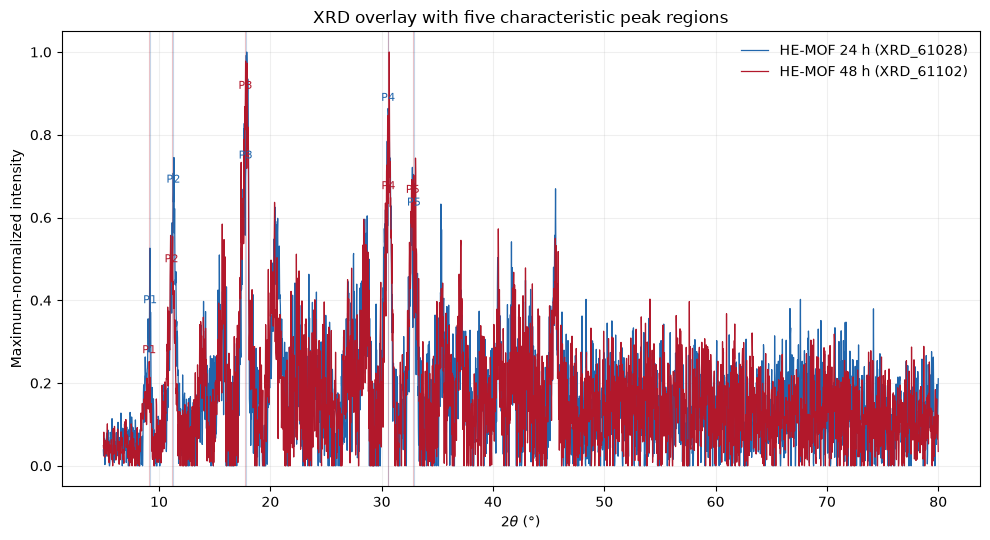

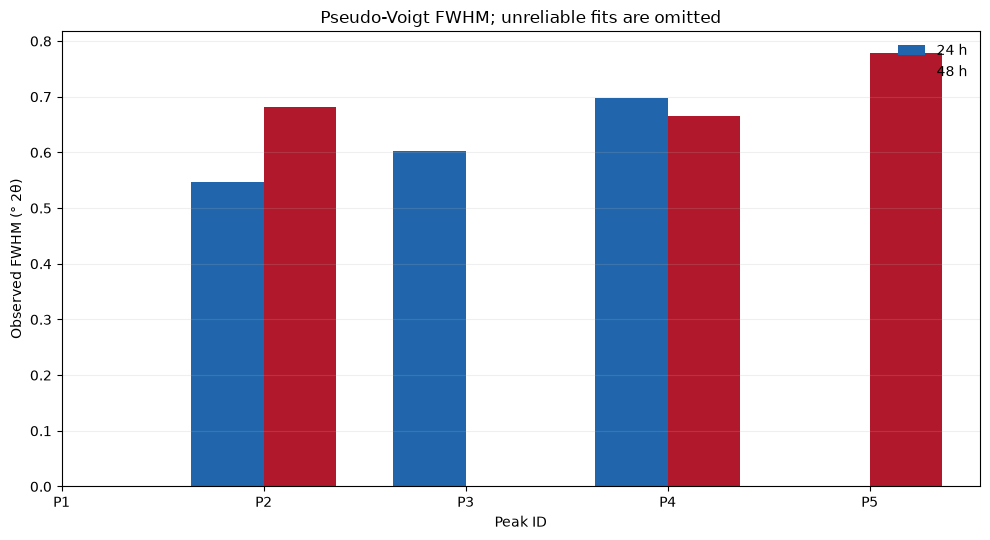

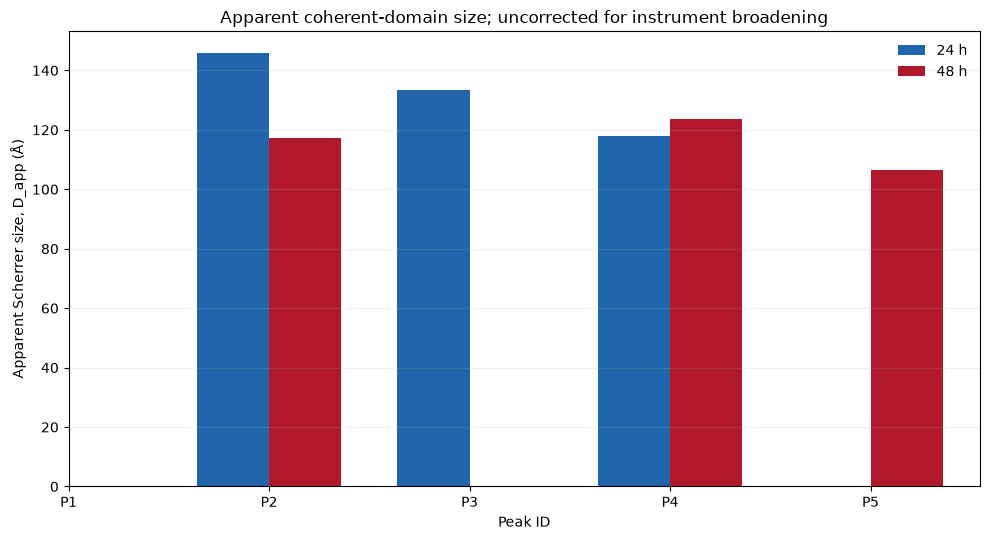

In [8]:
# Exactly three requested figures; all use the same five Peak IDs as the comparison table.
figures_to_export = []

fig, ax = plt.subplots(figsize=CONFIG["figure_size"])
figures_to_export.append(("five_peak_overlay", fig))
colors = {"sample_24h": "#2166ac", "sample_48h": "#b2182b"}
for key in sample_keys:
    spec = spectra[key]
    ax.plot(spec["theta"], spec["max_norm"], color=colors[key], lw=0.9, label=spec["label"])
    table = target_tables[key]
    for peak_id, row in table.iterrows():
        if np.isfinite(row["position_deg"]):
            ax.axvline(row["position_deg"], color=colors[key], alpha=0.25, lw=0.8)
            ax.annotate(peak_id, (row["position_deg"], np.interp(row["position_deg"], spec["theta"], spec["max_norm"])),
                        xytext=(0, 6), textcoords="offset points", ha="center", color=colors[key], fontsize=8)
ax.set(xlabel=r"2$\theta$ (°)", ylabel="Maximum-normalized intensity",
       title="XRD overlay with five characteristic peak regions")
ax.legend(frameon=False)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

ids = list(CONFIG["target_peak_regions_deg"])
x = np.arange(len(ids))
width = 0.36
fig, ax = plt.subplots(figsize=CONFIG["figure_size"])
figures_to_export.append(("five_peak_fwhm", fig))
fwhm24 = [target_tables["sample_24h"].loc[p, "fwhm_observed_deg"] for p in ids]
fwhm48 = [target_tables["sample_48h"].loc[p, "fwhm_observed_deg"] for p in ids]
ax.bar(x - width/2, fwhm24, width, color=colors["sample_24h"], label="24 h")
ax.bar(x + width/2, fwhm48, width, color=colors["sample_48h"], label="48 h")
ax.set(xticks=x, xticklabels=ids, xlabel="Peak ID", ylabel="Observed FWHM (° 2θ)",
       title="Pseudo-Voigt FWHM; unreliable fits are omitted")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=CONFIG["figure_size"])
figures_to_export.append(("five_peak_scherrer_d_app", fig))
d24 = [target_tables["sample_24h"].loc[p, "d_app_angstrom"] for p in ids]
d48 = [target_tables["sample_48h"].loc[p, "d_app_angstrom"] for p in ids]
ax.bar(x - width/2, d24, width, color=colors["sample_24h"], label="24 h")
ax.bar(x + width/2, d48, width, color=colors["sample_48h"], label="48 h")
ax.set(xticks=x, xticklabels=ids, xlabel="Peak ID", ylabel="Apparent Scherrer size, D_app (Å)",
       title="Apparent coherent-domain size; uncorrected for instrument broadening")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()


## V. Xuất kết quả

Xuất một bảng so sánh năm peak, metrics similarity/reference, thông số fit và cấu hình tái lập. Dữ liệu XRD gốc không bị sửa đổi.


In [9]:
OUTPUT_DIR = PROJECT_ROOT / CONFIG["output_dir"]
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

comparison_csv = OUTPUT_DIR / "five_peak_comparison.csv"
similarity_csv = OUTPUT_DIR / "xrd_similarity_metrics.csv"
reference_csv = OUTPUT_DIR / "reference_peak_matching.csv"
quality_csv = OUTPUT_DIR / "data_quality_report.csv"
five_peak_comparison.to_csv(comparison_csv, index=False)
similarity_table.to_csv(similarity_csv, index=False)
reference_match_table.to_csv(reference_csv, index=False)
quality_report.to_csv(quality_csv)

component_columns = [
    "fit_group_id", "fit_group_size", "detected_position_deg", "fit_center_deg",
    "fit_center_se_deg", "fwhm_observed_deg", "fwhm_se_deg", "fit_area",
    "fit_amplitude", "fit_eta_lorentzian", "fit_offset", "fit_rmse", "fit_r2",
    "fit_reduced_chi2", "fit_status", "fit_reliable", "source_peak_prominence",
]
fit_parameters = pd.concat([
    table.reindex(columns=component_columns).assign(sample=spectra[key]["label"])
    for key, table in fit_components.items()
], ignore_index=True)
fit_parameters.to_csv(OUTPUT_DIR / "five_peak_fit_parameters.csv", index=False)

metadata = {
    "config": {k: (str(v) if isinstance(v, Path) else v) for k, v in CONFIG.items()},
    "project_root": str(PROJECT_ROOT),
    "common_sample_range_deg_2theta": list(map(float, common_sample_range)),
    "common_all_range_deg_2theta": list(map(float, common_all_range)),
    "reference_type": "Digitized from a scientific-paper XRD plot; not an original experimental scan.",
    "reference_processing": "Sorted and averaged exact duplicate 2theta points only; raw unique points used for peak positions; no smoothing, baseline, width fit, or area fit.",
    "reference_similarity": "Only for pointwise correlation metrics, digitized reference intensities are linearly interpolated to the sample grid on common_all_range; this does not add measured reference data or affect peak-position matching.",
    "fit_method": "Grouped simultaneous pseudo-Voigt least-squares only for nearby candidates in the five target regions.",
    "fit_quality": {"minimum_r2": CONFIG["fit_min_r2"], "parameter_errors": "local Jacobian covariance estimate"},
    "scherrer": {"K": CONFIG["scherrer_k"], "wavelength_angstrom": CONFIG["wavelength_angstrom"],
                 "reported_quantity": "D_app from observed FWHM; no instrumental deconvolution",
                 "instrument_fwhm_deg_2theta": CONFIG["instrument_fwhm_deg_2theta"]},
    "peak_ids": "P1-P5 correspond to search regions, not constrained fit centers.",
}
(OUTPUT_DIR / "analysis_parameters.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
for name, figure in figures_to_export:
    figure.savefig(OUTPUT_DIR / f"{name}.png", dpi=CONFIG["figure_dpi"], bbox_inches="tight")

for output in (comparison_csv, similarity_csv, reference_csv, quality_csv, OUTPUT_DIR / "five_peak_fit_parameters.csv"):
    check = pd.read_csv(output)
    print(f"{output.name}: {len(check)} rows, {len(check.columns)} columns")
print(f"Saved three 300-DPI PNG figures and analysis_parameters.json in {OUTPUT_DIR}")


five_peak_comparison.csv: 5 rows, 17 columns
xrd_similarity_metrics.csv: 9 rows, 8 columns
reference_peak_matching.csv: 9 rows, 6 columns
data_quality_report.csv: 3 rows, 12 columns
five_peak_fit_parameters.csv: 12 rows, 18 columns
Saved three 300-DPI PNG figures and analysis_parameters.json in /var/local/DE_AN/XRD/XRD_61028/analysis/xrd_results
